In [1]:
#Necessary imports
import matplotlib.pyplot as plt
import numpy as np
import cv2
import os
import PIL
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential

In [2]:
!pip install opendatasets

In [3]:
#Importing open datasets
import opendatasets as od

In [4]:
#Downloading the dataset into the system

od.download('https://www.kaggle.com/datasets/navoneel/brain-mri-images-for-brain-tumor-detection')



Skipping, found downloaded files in ".\brain-mri-images-for-brain-tumor-detection" (use force=True to force download)


In [13]:
#Assigning the location of the data to a variable using pathlib
import pathlib

data_dir=pathlib.Path(r'C:\Users\admin\My Python Stuff\brain-mri')

In [15]:
data_dir

WindowsPath('C:/Users/admin/My Python Stuff/brain-mri')

In [17]:
#First five images in the dataset
list(data_dir.glob('*/*.jpg'))[:5]

[WindowsPath('C:/Users/admin/My Python Stuff/brain-mri/no/10 no.jpg'),
 WindowsPath('C:/Users/admin/My Python Stuff/brain-mri/no/11 no.jpg'),
 WindowsPath('C:/Users/admin/My Python Stuff/brain-mri/no/12 no.jpg'),
 WindowsPath('C:/Users/admin/My Python Stuff/brain-mri/no/13 no.jpg'),
 WindowsPath('C:/Users/admin/My Python Stuff/brain-mri/no/14 no.jpg')]

In [25]:
#Creating lists of the datasets having tumor an non-tumor
yes = list(data_dir.glob('yes/*'))
no=list(data_dir.glob('no/*'))

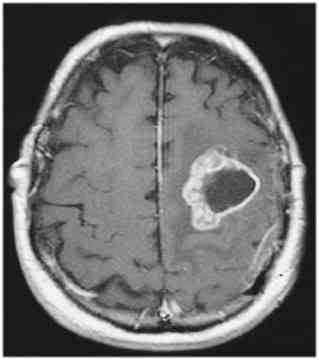

In [23]:
#Displaying first image in list having tumor using pillow lbrabry
PIL.Image.open(str(yes[1]))

**Read images from disk into numpy array using opencv**

In [121]:
images_dict= {
    'yes': list(data_dir.glob('yes/*')),
    'no':list(data_dir.glob('no/*'))
}

In [123]:
images_label_dictionary={
    'yes':0,
    'no': 1
}

In [125]:
images_dict['no'][:3]

[WindowsPath('C:/Users/admin/My Python Stuff/brain-mri/no/1 no.jpeg'),
 WindowsPath('C:/Users/admin/My Python Stuff/brain-mri/no/10 no.jpg'),
 WindowsPath('C:/Users/admin/My Python Stuff/brain-mri/no/11 no.jpg')]

In [127]:
str(images_dict['no'][1])

'C:\\Users\\admin\\My Python Stuff\\brain-mri\\no\\10 no.jpg'

In [129]:
#Reading the image using open cv
img=cv2.imread(str(images_dict['no'][1]))

In [131]:
img.shape

(201, 173, 3)

In [225]:
x, y= [], []

for if_tumor, images in images_dict.items():
    for image in images:
        img=cv2.imread(str(image))
        resized_img=cv2.resize(img,(180,180))
        x.append(resized_img)
        y.append(images_label_dictionary[if_tumor])

In [227]:
x = np.array(x)
y = np.array(y)

In [235]:
# Splitting the data using train test split
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, random_state=0)

In [237]:
x_train_scaled = x_train / 255
x_test_scaled = x_test / 255

In [233]:
print(x_train_scaled.shape)



(189, 180, 180, 3)


In [239]:
#Build a convultion neural network and train it
num_classes = 2

model = Sequential([
  layers.Conv2D(16, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Conv2D(32, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Conv2D(64, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Flatten(),
  layers.Dense(128, activation='relu'),
  layers.Dense(num_classes)
])

model.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])
              
model.fit(x_train_scaled, y_train, epochs=30)     

Epoch 1/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 333ms/step - accuracy: 0.5979 - loss: 1.1846
Epoch 2/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 343ms/step - accuracy: 0.7831 - loss: 0.5327
Epoch 3/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 348ms/step - accuracy: 0.7937 - loss: 0.4919
Epoch 4/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 381ms/step - accuracy: 0.8254 - loss: 0.4232
Epoch 5/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 392ms/step - accuracy: 0.8413 - loss: 0.3785
Epoch 6/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 411ms/step - accuracy: 0.8730 - loss: 0.3248
Epoch 7/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 407ms/step - accuracy: 0.9153 - loss: 0.2506
Epoch 8/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 371ms/step - accuracy: 0.9259 - loss: 0.1906
Epoch 9/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 392ms/step - accuracy: 0.9259 - loss: 0.1496
Epoch 10/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 446ms/step - accuracy: 0.9735 - loss: 0.1188
Epoch 11/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 379ms/step - accuracy: 0.9577 - loss: 0.0959
Epoch 12/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 368ms/step - accuracy: 0.9524 - lo

In [241]:
model.evaluate(x_test_scaled,y_test)

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 167ms/step - accuracy: 0.8594 - loss: 0.8311


[0.8310628533363342, 0.859375]

In [243]:
predictions = model.predict(x_test_scaled)
predictions

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 129ms/step


array([[ -6.199197  ,   5.0596595 ],
       [  8.078276  ,  -8.344044  ],
       [  7.594491  ,  -8.177327  ],
       [  8.899184  ,  -9.54982   ],
       [ -0.4047187 ,  -0.26820084],
       [ -3.8372583 ,   1.3279542 ],
       [ 10.622382  , -10.455589  ],
       [ -9.127954  ,   6.956462  ],
       [  6.092698  ,  -6.9544134 ],
       [  7.4616423 ,  -8.350974  ],
       [  4.3063035 ,  -5.9476023 ],
       [  4.8117547 ,  -5.302884  ],
       [  6.6911116 ,  -6.700604  ],
       [ -4.6166606 ,   3.341604  ],
       [  3.7893355 ,  -4.9096613 ],
       [  5.033796  ,  -7.1471996 ],
       [ -0.6683551 ,  -1.4502405 ],
       [-10.785275  ,   8.059202  ],
       [ -1.3022546 ,   1.6373245 ],
       [  9.665625  , -10.967497  ],
       [ -5.35853   ,   1.4413139 ],
       [  5.92736   ,  -8.784033  ],
       [  1.8481475 ,  -4.528153  ],
       [  6.2313123 ,  -9.017126  ],
       [  4.164623  ,  -5.632044  ],
       [ -9.490311  ,   5.019514  ],
       [  7.51987   ,  -8.1718645 ],
 

In [245]:
score = tf.nn.softmax(predictions[0])

In [247]:
np.argmax(score)

1

In [249]:
y_test[0]

1